### Ratios from Fundamental Data

- Current Ratio
- Return on Equity (ROE)
- Debt to Equity (D/E) Ratio

In [2]:
import os
import sys
sys.path.append("..")

# Import the SimFin library
import simfin as sf

# Import the names used for easy access to SimFin's data-columns
from simfin.names import *

# Import time manipulation library
from datetime import timedelta

# Import data manipulation library
import pandas as pd

# Import matplotlib and set the style for plotting
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

### Fundamental Data

#### Getting the simfin API key

In [3]:
# Input your simfin API key
simfin_api_key = "your_api_key_here"

# Input your simfin API key
simfin_api_key = "aa4fab92-4f88-4532-8a51-fedb2925190e"

# SimFin data-directory
sf.set_data_dir('~/simfin_data/')

# SimFin API key
sf.config.set_api_key(api_key=simfin_api_key)

### Define the Stock Ticker and Fetch Fundamental Data

In [4]:
# Set the market as US
market = 'us'

# Define the stock ticker
stock_ticker = 'AAPL'

# Fetch quarterly income statements for all the tickers in SimFin database
income_data_simfin_all_stocks = sf.load_income(variant='quarterly', market=market)
income_data = income_data_simfin_all_stocks.loc[stock_ticker,:]

# Fetch quarterly balance sheet data for all the tickers in SimFin database
balance_sheet_data = sf.load_balance(variant='quarterly', market=market)
balance_sheet_data = balance_sheet_data.loc[stock_ticker,:]

# Fetch quarterly cash flow data for all the tickers in SimFin database
cash_flow_data = sf.load_balance(variant='quarterly', market=market)
cash_flow_data = cash_flow_data.loc[stock_ticker,:]

Dataset "us-income-quarterly" on disk (0 days old).
- Loading from disk ... Done!
Dataset "us-balance-quarterly" on disk (0 days old).
- Loading from disk ... Done!
Dataset "us-balance-quarterly" on disk (0 days old).
- Loading from disk ... Done!


### Current Ratio

The current ratio is a liquidity ratio that measures a company's ability to pay short-term obligations. For an investor, a very high current ratio is not a good indicator because that indicates that the company is not using its current assets efficiently. A current ratio of less than 1 is also not a good sign because that indicates that the company may have problems meeting its short term obligations.
The current ratio is calculated as:

$$Current\ ratio= \frac{Total\ Current\ Assets} {Total\ Current\ Liabilities}$$

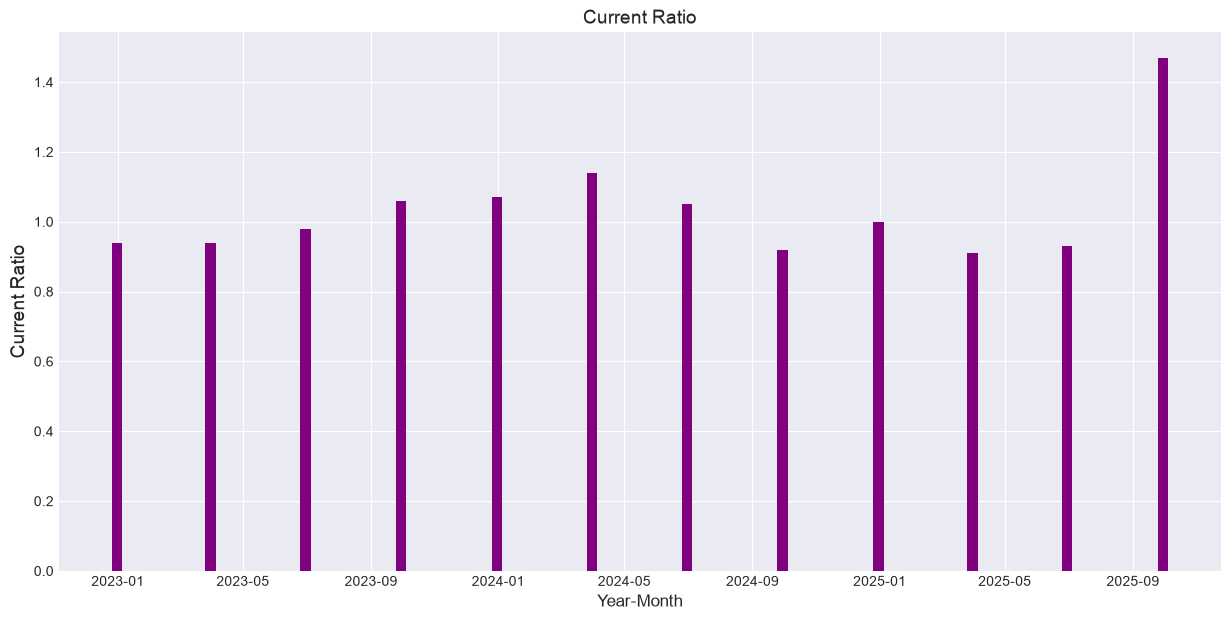

In [6]:
# Calculate the current ratio
current_ratio = round((balance_sheet_data['Total Current Assets'] / balance_sheet_data['Total Current Liabilities']).astype(float), 2)

# Plot the current ratio for the last 3 years
data_to_plot = current_ratio.tail(12)
X = data_to_plot.index
plt.figure(figsize=[15,7])

# Plot the bar chart
plt.bar(X, data_to_plot, color='purple', width=10, label='Current Ratio')

# Set title and labels for the plot
plt.title('Current Ratio', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Current Ratio', fontsize=14)
plt.show()

### Return on Equity (ROE)

The return on equity (ROE) is a measure of the profitability of a business with respect to its equity. Usually, the larger the ROE is, the better it is for the company.
The return on equity is calculated as:

$$Return\ on\ equity\ (ROE) (\%)\ = \frac{Net Income}{Total\ Equity\ *\ 100}$$

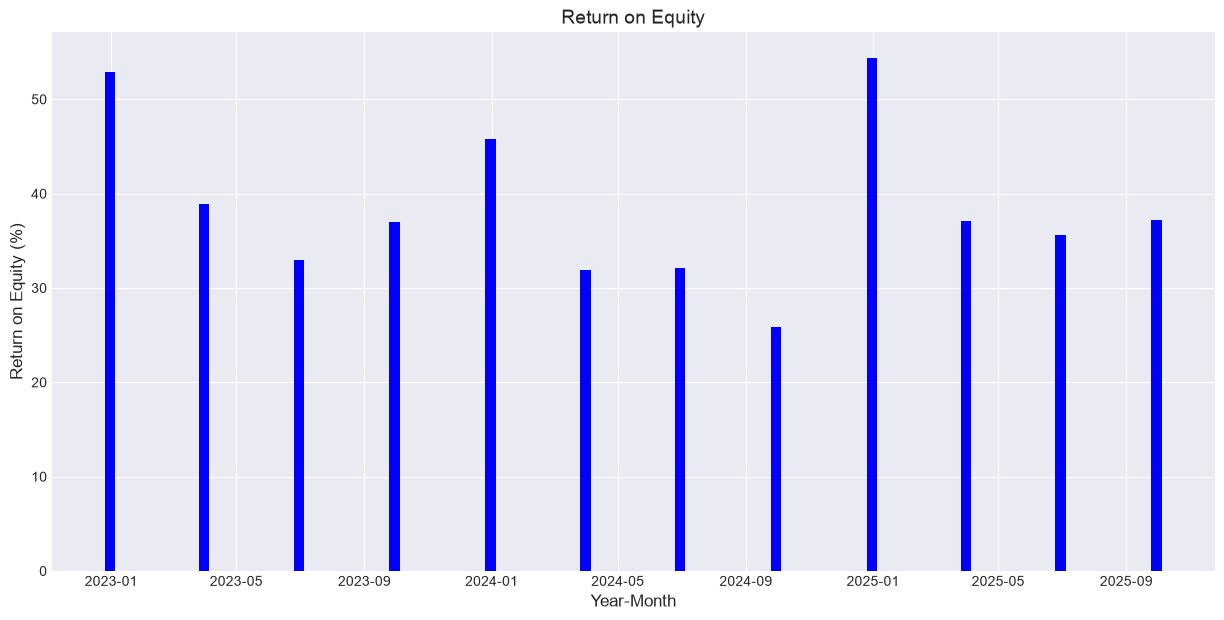

In [8]:
# Calculate the return on equity
return_on_equity =round((income_data['Net Income'] / balance_sheet_data['Total Equity'] * 100).astype(float), 2)

# Plot the return on equity for the last 3 years
data_to_plot = return_on_equity.tail(12)
X = data_to_plot.index
plt.figure(figsize=[15,7])

# Plot the bar chart
plt.bar(X, data_to_plot, color='blue', width=10, label='Return on Equity')

# Set title and labels for the plot
plt.title('Return on Equity', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Return on Equity (%)', fontsize=12)
plt.show()

### Debt to Equity (D/E) Ratio

The debt to equity (D/E) ratio is a fundamental ratio indicating the relative proportion of shareholders' equity and debt used to finance a company's assets. The ratio is also known as risk, gearing or leverage. A high D/E ratio is considered risky because it suggests that the company is financing a significant amount of its potential growth through borrowing.

The debt to equity ratio is calculated as:

$$Debt\ to\ Equity\ Ratio\ (D/E) = \frac{Long\ Term\ Debt}{Total\ Equity}$$

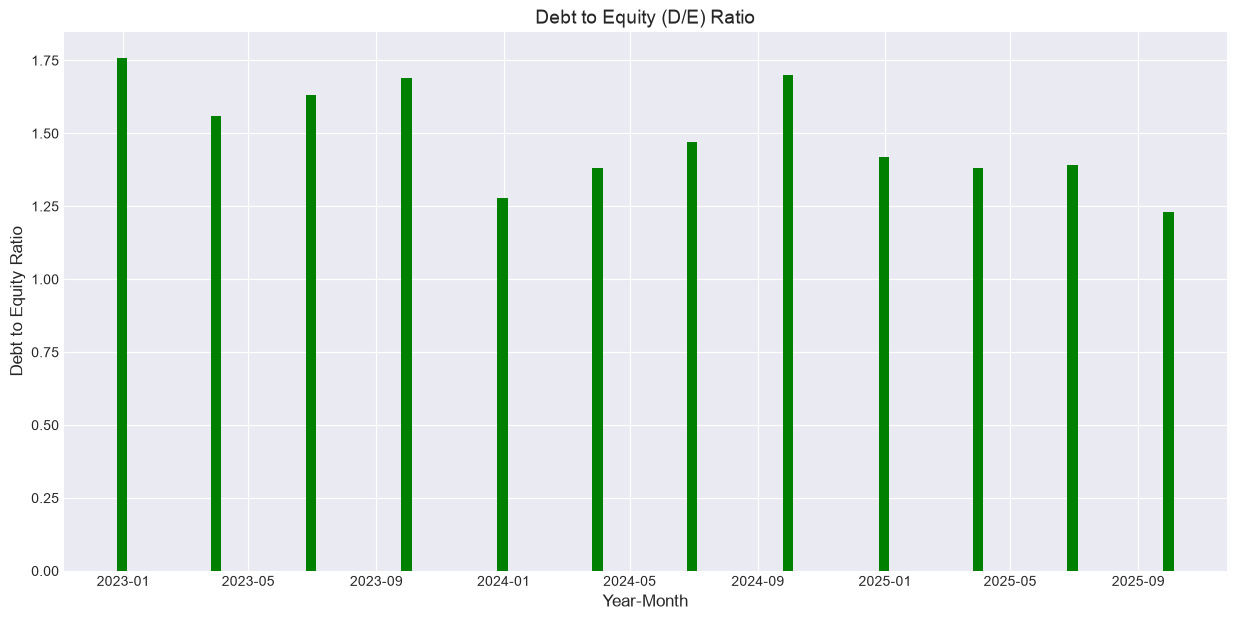

In [9]:
# Calculate the debt to equity ratio
de_ratio = round((balance_sheet_data['Long Term Debt'] / balance_sheet_data['Total Equity']).astype(float), 2)

# Plot the debt to equity for the last 3 years
data_to_plot = de_ratio.tail(12)
X = data_to_plot.index
plt.figure(figsize=[15,7])

# Plot the bar chart
plt.bar(X, data_to_plot, color='green', width=10, label='Debt to Equity (D/E) Ratio')

# Set title and labels for the plot
plt.title('Debt to Equity (D/E) Ratio', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Debt to Equity Ratio', fontsize=12)
plt.show()